# F12: unfolding k-meshes reduced by the point group

**Finding** (`notes/theory_audit.md`, F12): with JDFTx's default `symmetries automatic`, the k-mesh is reduced by
the space group. Each computed k-point stands in for its whole star, so single bonds, m-resolved orbitals and
single atoms of an equivalent set can't be read off it. Since F5 crawfish guarded such meshes: single-image pair
spectra raised, and `image="all"` pair spectra and partial pDOS warned and returned symmetry-averaged values.

**Fix:** with `dump End Symmetries`, JDFTx writes its operations (the `sym` file). crawfish now rebuilds every
full-mesh state from the computed state its k-point is an image of: the operation permutes the atoms, rotates each
orbital shell (JDFTx's real spherical harmonics), and multiplies by the Bloch phase of the lattice vector a mapped
atom moves by; time reversal conjugates where needed. Setting `unfold_point_group=False` restores the F5 behaviour
(the `legacy` column below).

Fixtures: `graphene_zspin_pg` (24 operations, 19 of 144 k per spin) against the full-mesh SCF run
`graphene_zspin_full`; `ZnO_wurtzite_pg` (12 operations with c/2 screws, no inversion, Zn d orbitals, 8 of 48 k)
against `ZnO_wurtzite_full`, the full mesh computed at the same density. Figures are saved to `figures/`. The last
cell holds the tests.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))  # fixcompare.py lives next to this notebook (run with this directory as cwd)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from fixcompare import *
from crawfish.funcs import get_pcohp
from crawfish.funcs.pcohp import _get_pcohp_tj
from crawfish.funcs.dos import get_pdos_tj
from crawfish.utils.indexing import get_orb_idcs

FIXED_C, LEGACY_C, REF_C = "#2a78d6", "#eb6834", "#5f5e5a"  # categorical slots 1 and 2; the reference is neutral
D = Path(EXAMPLE_CALC_DIRS_DIR)


def quiet(f, *args, **kwargs):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")  # the 20-band graphene runs warn about too few bands (F11)
        return f(*args, **kwargs)


def icohp(edata, a, b, image, orbs=None):
    """Occupied IpCOHP (Ha), or None where crawfish refuses (single images on a reduced mesh)."""
    try:
        w = quiet(_get_pcohp_tj, edata, a, None, orbs, b, None, orbs, use_cache=False, image=image)
    except ValueError:
        return None
    return float(np.sum(edata.occ_tj * w))


def ipdos(edata, idx, orbs):
    """Occupied pDOS of one atom's orbitals (electrons)."""
    return float(np.sum(edata.occ_tj * get_pdos_tj(edata.proj_tju, get_orb_idcs(edata, idx, None, orbs), edata.wk_t)))


gr = {"legacy": quiet(load_edata_at, "F12", False, D / "graphene_zspin_pg"),
      "unfolded": quiet(load_edata_at, "F12", True, D / "graphene_zspin_pg"),
      "full mesh": quiet(load_edata, D / "graphene_zspin_full")}
zno = {"legacy": quiet(load_edata_at, "F12", False, D / "ZnO_wurtzite_pg"),
       "unfolded": quiet(load_edata_at, "F12", True, D / "ZnO_wurtzite_pg"),
       "full mesh": quiet(load_edata, D / "ZnO_wurtzite_full")}
summary = pd.DataFrame({
    name: {"operations (sym)": len(sets["unfolded"].kmesh_unfolding["ops"]),
           "computed states": sets["unfolded"].nstates_file,
           "full-mesh states": sets["unfolded"].nstates,
           "states needing time reversal": int(sets["unfolded"].kmesh_unfolding["conj_t"].sum()),
           "legacy: mesh reduced": sets["legacy"].kmesh_is_reduced}
    for name, sets in [("graphene", gr), ("ZnO", zno)]}).T
summary

,operations (sym),computed states,full-mesh states,states needing time reversal,legacy: mesh reduced
graphene,24,38,288,0,True
ZnO,12,8,48,16,True


## Which k-points are lumped together: graphene on a 3x3 mesh

The smallest useful example: graphene's cell (a₁ = a(1, 0), a₂ = a(−½, √3/2)) with a Γ-centred 3x3 mesh, k =
(i/3, j/3) in reciprocal-lattice coordinates. An operation g = (rot, a) of the crystal maps a Bloch state at k onto
one at rot⁻ᵀk, with the same eigenvalues, so the two k-points carry the same information and JDFTx computes only one.
Graphene has 24 operations (the hexagonal point group D6h, which includes inversion). Applied to the 9 k-points they
form three groups:

- **Γ** on its own (every operation leaves it in place);
- **six points** ⅔ of the way from Γ to the six M points, related by rotations through multiples of 60°;
- **K and K′**, the two Dirac points, related by inversion (k → −k, drawn as a 180° turn), or by a 60° rotation
  onto one of K′'s equivalent zone corners.

Time reversal alone (k → −k, what F5 unfolds) only pairs each point with its negative, so it leaves 5 groups: the
six points split into three ± pairs, because only a rotation turns one direction into another.

The groups below are computed from the operations in `graphene_zspin_pg/sym` (the same cell). They are checked
against what JDFTx did for this mesh: `kpoint-folding 3 3 1` on the `graphene_zspin_pg` input, no-spin, run
2026-10-28, wrote the `kPts` and `kMap` quoted in the cell. The weights carry the spin factor 2 of no-spin runs.

In [2]:
from crawfish.io.data_parsing import get_kmesh_unfolding
from crawfish.utils.symmetry import get_cartesian_rotation

# What JDFTx wrote for graphene_zspin_pg's input with kpoint-folding 3 3 1 (no-spin): the computed k-points with
# their weights (kPts), and for each of the 9 mesh points the computed one it comes from (kMap, first column)
JDFTX_REDUCED = {(0.0, 0.0): 0.222222222, (0.0, 1 / 3): 1.333333333, (1 / 3, 1 / 3): 0.444444444}
JDFTX_KMAP_SRC = [0, 1, 1, 1, 2, 1, 1, 1, 2]
JDFTX_TR_ONLY = 5  # 'symmetries manual' with only the identity: "Reduced to 5 k-points under symmetry."

ed = gr["unfolded"]
ops = ed.kmesh_unfolding["ops"]
lattice = ed.structure.lattice.matrix
rec = ed.structure.lattice.reciprocal_lattice.matrix  # rows b1, b2, b3 (2 pi / Angstrom)
# JDFTx's mesh order (i0 slowest), each coordinate reduced to (-0.5, 0.5]
mesh = np.array([[i / 3, j / 3, 0.0] for i in range(3) for j in range(3)])
mesh[mesh > 0.5] -= 1.0


def same_k(k1, k2):
    d = np.asarray(k1) - np.asarray(k2)
    return np.abs(d - np.round(d)).max() < 1e-6


def image(rot, k):
    return np.round(np.linalg.inv(rot), 6).T @ k  # rot^-T k


def describe(rot):
    """The operation's action in the k_z = 0 plane (its z part doesn't matter for these k-points)."""
    s = get_cartesian_rotation(rot, lattice)[:2, :2]
    if np.linalg.det(s) > 0:
        angle = np.degrees(np.arctan2(s[1, 0], s[0, 0]))
        return "identity" if abs(angle) < 1e-6 else f"rotate {angle:+.0f}°"
    return f"mirror across the {np.degrees(np.arctan2(s[1, 0], s[0, 0])) / 2 % 180:.0f}° line"


def simplicity(rot):
    """Sort key: the identity first, then rotations by their angle, then mirrors."""
    d = describe(rot)
    return (d != "identity", d.startswith("mirror"), abs(float(d.split()[1].rstrip("°"))) if d.startswith("rotate") else 0)


def groups(rots):
    """Orbits of the mesh under the operations; each represented by its first point in JDFTx's order."""
    rep = [-1] * len(mesh)
    for i, k in enumerate(mesh):
        if rep[i] < 0:
            for j, k2 in enumerate(mesh):
                if rep[j] < 0 and any(same_k(image(r, k), k2) for r in rots):
                    rep[j] = i
    return rep


rep_pg = groups([rot for rot, _ in ops])
rep_tr = groups([np.eye(3), -np.eye(3)])  # time reversal: k -> -k
names = {0: "Γ", 1: "Γ–M points", 4: "K, K′"}
rows = []
for i, k in enumerate(mesh):
    r = rep_pg[i]
    maps = [rot for rot, _ in ops if same_k(image(rot, mesh[r]), k)]
    best = min(maps, key=simplicity)
    rows.append({"k (k1, k2)": f"({k[0]:+.3f}, {k[1]:+.3f})", "group": names[r],
                 "computed point": f"({mesh[r][0]:+.3f}, {mesh[r][1]:+.3f})", "simplest operation": describe(best),
                 "operations that do it": len(maps),
                 "time reversal alone pairs it with": next(
                     (f"({mesh[j][0]:+.3f}, {mesh[j][1]:+.3f})" for j in range(len(mesh)) if j != i and rep_tr[j] == rep_tr[i]),
                     "itself")})
lumped = pd.DataFrame(rows)
lumped

,"k (k1, k2)",group,computed point,simplest operation,operations that do it,time reversal alone pairs it with
0,"(+0.000, +0.000)",Γ,"(+0.000, +0.000)",identity,24,itself
1,"(+0.000, +0.333)",Γ–M points,"(+0.000, +0.333)",identity,4,"(+0.000, -0.333)"
2,"(+0.000, -0.333)",Γ–M points,"(+0.000, +0.333)",rotate +180°,4,"(+0.000, +0.333)"
3,"(+0.333, +0.000)",Γ–M points,"(+0.000, +0.333)",rotate -60°,4,"(-0.333, +0.000)"
4,"(+0.333, +0.333)","K, K′","(+0.333, +0.333)",identity,12,"(-0.333, -0.333)"
5,"(+0.333, -0.333)",Γ–M points,"(+0.000, +0.333)",rotate -120°,4,"(-0.333, +0.333)"
6,"(-0.333, +0.000)",Γ–M points,"(+0.000, +0.333)",rotate +120°,4,"(+0.333, +0.000)"
7,"(-0.333, +0.333)",Γ–M points,"(+0.000, +0.333)",rotate +60°,4,"(+0.333, -0.333)"
8,"(-0.333, -0.333)","K, K′","(+0.333, +0.333)",rotate -60°,12,"(+0.333, +0.333)"


Each computed point stands for |group| = 24 / (operations that leave it in place) mesh points: Γ for 1, a Γ–M
point for 6 (each is fixed by 4 of the 24 operations), K for 2 (fixed by 12). Those counts are the weights JDFTx
gives the computed points, and crawfish's map (`get_kmesh_unfolding`) reproduces JDFTx's `kMap`.

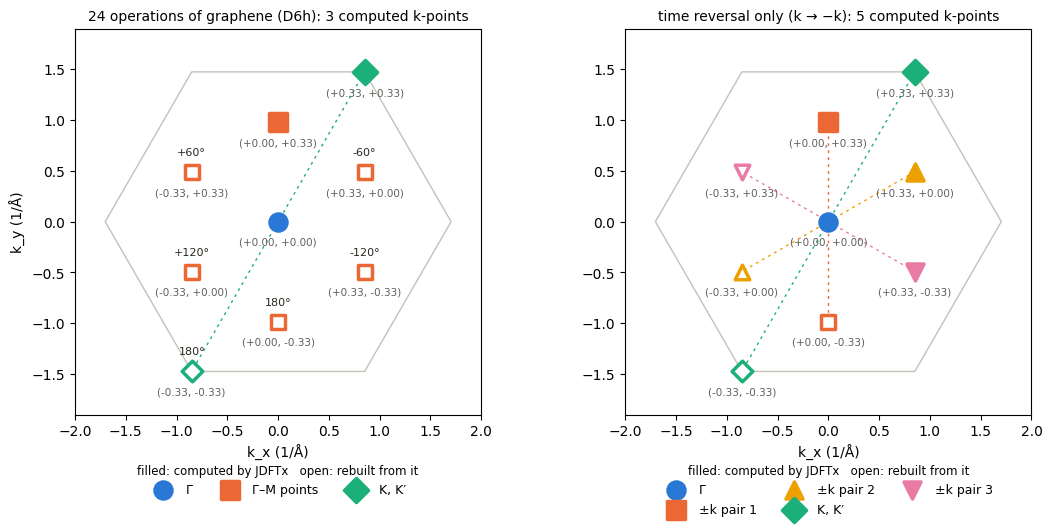

In [3]:
# Weights: |group| / 9, times the no-spin factor 2, as JDFTx wrote them
for (k1, k2), w in JDFTX_REDUCED.items():
    r = next(i for i, k in enumerate(mesh) if same_k(k, [k1, k2, 0]))
    assert abs(2 * rep_pg.count(r) / 9 - w) < 1e-8
assert len(set(rep_tr)) == JDFTX_TR_ONLY and len(set(rep_pg)) == len(JDFTX_REDUCED)
# crawfish's unfolding map, from the 3 computed points and JDFTx's weights, against JDFTx's kMap
reduced = [mesh[r] for r in sorted(set(rep_pg))]
unfolding = get_kmesh_unfolding(np.array(reduced), np.array(list(JDFTX_REDUCED.values())), 1, [3, 3, 1], [0, 0, 0],
                                rots=[rot for rot, _ in ops])
assert list(unfolding["src_t"]) == JDFTX_KMAP_SRC

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), layout="constrained")
cart = mesh @ rec
# Show each point at its image nearest Γ, inside the hexagonal Brillouin zone
shifts = np.array([[i, j, 0] for i in (-1, 0, 1) for j in (-1, 0, 1)]) @ rec
cart = np.array([min(c + shifts, key=lambda v: (round(np.linalg.norm(v), 6), -v[0], -v[1])) for c in cart])
cart[8] = -cart[4]  # K' = -K: of its three equivalent zone corners, draw the one opposite K
k_mag = np.linalg.norm(cart[4])  # K: |K| is the corner distance of the zone
hexagon = np.array([[np.cos(t), np.sin(t)] for t in np.radians(np.arange(0, 361, 60) + np.degrees(
    np.arctan2(cart[4][1], cart[4][0])))]) * k_mag
# Categorical slots 1-5 in their fixed order; each group keeps its colour and marker in both panels: Γ slot 1, the
# Γ-M points slot 2 (their first ± pair keeps it, the other pairs take slots 4 and 5), K/K' slot 3
STYLE = {"Γ": ("#2a78d6", "o"), "Γ–M points": ("#eb6834", "s"), "K, K′": ("#1baf7a", "D"),
         "±k pair 1": ("#eb6834", "s"), "±k pair 2": ("#eda100", "^"), "±k pair 3": ("#e87ba4", "v")}
panels = [("24 operations of graphene (D6h)", rep_pg), ("time reversal only (k → −k)", rep_tr)]
for ax, (title, rep) in zip(axes, panels):
    ax.plot(hexagon[:, 0], hexagon[:, 1], color="#c3c2b7", linewidth=1)
    npairs = 0
    for r in sorted(set(rep)):
        members = [i for i, x in enumerate(rep) if x == r]
        if r == 0:
            label = "Γ"
        elif 4 in members:
            label = "K, K′"
        elif len(members) == 6:
            label = "Γ–M points"
        else:
            npairs += 1
            label = f"±k pair {npairs}"
        color, marker = STYLE[label]
        for i in members:
            computed = i == r
            ax.scatter(*cart[i, :2], s=150 if computed else 110, marker=marker,
                       facecolor=color if computed else "white", edgecolor=color, linewidth=2.5, zorder=3,
                       label=label if computed else None)
            ax.annotate(f"({mesh[i][0]:+.2f}, {mesh[i][1]:+.2f})", cart[i, :2], xytext=(0, -17),
                        textcoords="offset points", ha="center", fontsize=7.5, color="#5f5e5a")
        if len(members) == 2 and r != 0:  # ± pairs and K/K': a line through Γ shows k -> -k
            ax.plot(*cart[members, :2].T, color=color, linewidth=1, linestyle=(0, (2, 3)), zorder=1)
    ax.set_aspect("equal")
    ax.set_xlim(-2.0, 2.0)
    ax.set_ylim(-1.9, 1.9)
    ax.set_xlabel("k_x (1/Å)")
    ax.set_title(f"{title}: {len(set(rep))} computed k-points", fontsize=10)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=9,
              title="filled: computed by JDFTx   open: rebuilt from it", title_fontsize=8.5)
axes[0].set_ylabel("k_y (1/Å)")
# Label each rebuilt point with the rotation that carries the computed point onto it as drawn
for i in range(len(mesh)):
    r = rep_pg[i]
    if i != r:
        turn = np.degrees(np.arctan2(*cart[i, 1::-1]) - np.arctan2(*cart[r, 1::-1]))
        turn = (turn + 180) % 360 - 180
        axes[0].annotate("180°" if abs(abs(turn) - 180) < 1 else f"{turn:+.0f}°", cart[i, :2], xytext=(0, 12), textcoords="offset points", ha="center",
                         fontsize=8, color="#28261f")
savefig(fig, "F12_graphene_3x3_groups")
plt.show()

The fixtures use the same cell on a 12x12 mesh: there JDFTx computes 19 of the 144 k-points per spin, and
crawfish rebuilds the other 125 the same way. Rebuilding a point means more than copying eigenvalues: the operation
also rotates each orbital shell (here px and py into combinations of each other), may exchange the two C atoms,
and adds the Bloch phase of the cell an atom lands in. That is what the rest of this notebook checks.

## Graphene: single bonds and m-resolved orbitals

Before the fix (legacy), single bonds raised and the m-resolved quantities were averaged over the star: the
px–px pCOHP summed over all images came out twice the full-mesh value, because each computed k-point's px stood
in for its rotated copies, which are mostly py. Unfolded, every quantity matches the full-mesh run.

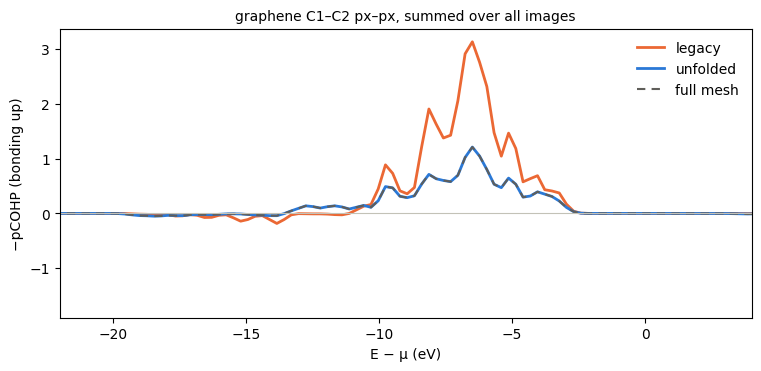

,legacy,unfolded,full mesh
"IpCOHP C1–C2 bond R=(0,0,0)",raises,-0.50126,-0.50126
"IpCOHP C1–C2 bond R=(-1,0,0)",raises,-0.50126,-0.50126
"IpCOHP C1–C2 bond R=(0,1,0)",raises,-0.50126,-0.50126
"IpCOHP C1–C2 px–px, R=(0,0,0)",raises,-0.06650,-0.06650
"IpCOHP C1–C2 px–px, all images",-0.31527,-0.14880,-0.14880
C1 s occupied pDOS,+0.90055,+0.90055,+0.90056
C1 px occupied pDOS,+0.98570,+1.03889,+1.03889
C1 py occupied pDOS,+1.09208,+1.03889,+1.03889
C1 pz occupied pDOS,+0.98847,+0.98847,+0.98848


In [4]:
fig, ax = plt.subplots(figsize=(7.5, 3.6), layout="constrained")
styles = {"legacy": dict(color=LEGACY_C, linewidth=2), "unfolded": dict(color=FIXED_C, linewidth=2),
          "full mesh": dict(color=REF_C, linewidth=1.5, linestyle=(0, (4, 3)))}
for name, edata in gr.items():
    erange, spec = quiet(get_pcohp, edata, idcs1=0, idcs2=1, orbs1="px", orbs2="px", image="all", sig=2e-4)
    ax.plot(to_ev_rel_mu(edata, erange), -np.asarray(spec), label=name, **styles[name])
ax.axhline(0, color="#c3c2b7", linewidth=0.8)
ax.set_xlim(-22, 4)
ax.set_xlabel("E − μ (eV)")
ax.set_ylabel("−pCOHP (bonding up)")
ax.set_title("graphene C1–C2 px–px, summed over all images", fontsize=10)
ax.legend(frameon=False)
savefig(fig, "F12_graphene_pxpx")
plt.show()

rows = {}
for label, (a, b, image, orbs) in {"C1–C2 bond R=(0,0,0)": (0, 1, [0, 0, 0], None),
                                   "C1–C2 bond R=(-1,0,0)": (0, 1, [-1, 0, 0], None),
                                   "C1–C2 bond R=(0,1,0)": (0, 1, [0, 1, 0], None),
                                   "C1–C2 px–px, R=(0,0,0)": (0, 1, [0, 0, 0], "px"),
                                   "C1–C2 px–px, all images": (0, 1, "all", "px")}.items():
    rows[f"IpCOHP {label}"] = {name: icohp(e, a, b, image, orbs) for name, e in gr.items()}
for orbs in ["s", "px", "py", "pz"]:
    rows[f"C1 {orbs} occupied pDOS"] = {name: quiet(ipdos, e, 0, orbs) for name, e in gr.items()}
gr_table = pd.DataFrame(rows).T
gr_table.style.format(lambda v: "raises" if v is None or pd.isna(v) else f"{v:+.5f}")

## ZnO: axial and basal Zn–O bonds, Zn d orbitals

Wurtzite has one axial Zn–O bond (1.989 Å) and three basal ones (1.974 Å). On the reduced mesh none of them could
be computed. Unfolded, both match the full mesh computed at the same density.

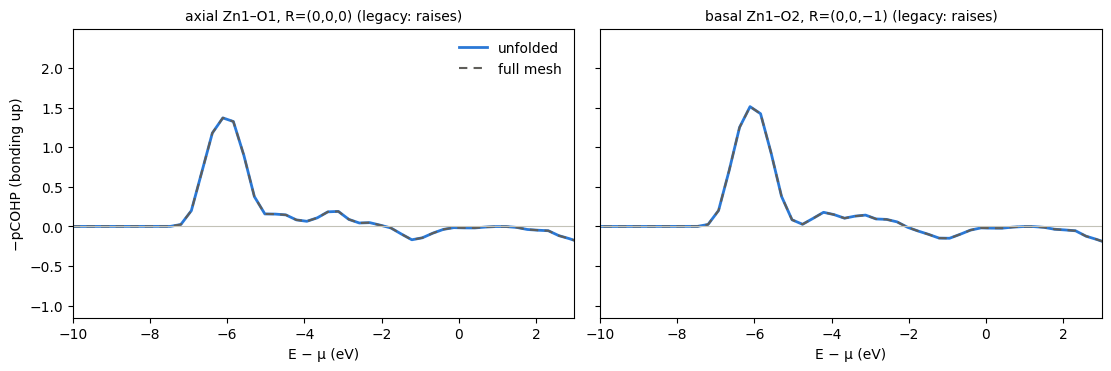

,legacy,unfolded,full mesh
"IpCOHP axial Zn1–O1, R=(0,0,0)",raises,-0.14438,-0.14438
"IpCOHP basal Zn1–O2, R=(0,0,−1)",raises,-0.14943,-0.14941
"IpCOHP basal Zn1–O2, R=(0,1,−1)",raises,-0.14942,-0.14943
"IpCOHP Zn1 dz2–O pz, all images",-0.00131,-0.00129,-0.00129
Zn1 dxy occupied pDOS,+1.99518,+1.99269,+1.99269
Zn1 dxz occupied pDOS,+1.99689,+1.99589,+1.99589
Zn1 dz2 occupied pDOS,+1.98996,+1.99002,+1.99002
Zn1 0px occupied pDOS,+1.99775,+1.99834,+1.99834
Zn1 0pz occupied pDOS,+1.99836,+1.99837,+1.99837


In [5]:
bonds = {"axial Zn1–O1, R=(0,0,0)": (2, [0, 0, 0]), "basal Zn1–O2, R=(0,0,−1)": (3, [0, 0, -1])}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, (title, (b, image)) in zip(axes, bonds.items()):
    for name in ["unfolded", "full mesh"]:
        edata = zno[name]
        erange, spec = quiet(get_pcohp, edata, idcs1=0, idcs2=b, image=image, sig=2e-4)
        ax.plot(to_ev_rel_mu(edata, erange), -np.asarray(spec), label=name, **styles[name])
    ax.axhline(0, color="#c3c2b7", linewidth=0.8)
    ax.set_xlim(-10, 3)
    ax.set_xlabel("E − μ (eV)")
    ax.set_title(f"{title} (legacy: raises)", fontsize=10)
axes[0].set_ylabel("−pCOHP (bonding up)")
axes[0].legend(frameon=False)
savefig(fig, "F12_zno_bonds")
plt.show()

rows = {f"IpCOHP {t}": {name: icohp(e, 0, b, image) for name, e in zno.items()} for t, (b, image) in bonds.items()}
rows["IpCOHP basal Zn1–O2, R=(0,1,−1)"] = {name: icohp(e, 0, 3, [0, 1, -1]) for name, e in zno.items()}
rows["IpCOHP Zn1 dz2–O pz, all images"] = {
    name: quiet(lambda e: float(np.sum(e.occ_tj * _get_pcohp_tj(e, 0, None, "dz2", [2, 3], None, "pz", use_cache=False,
                                                                image="all"))), e) for name, e in zno.items()}
for orbs in ["dxy", "dxz", "dz2", "0px", "0pz"]:
    rows[f"Zn1 {orbs} occupied pDOS"] = {name: quiet(ipdos, e, 0, orbs) for name, e in zno.items()}
zno_table = pd.DataFrame(rows).T
zno_table.style.format(lambda v: "raises" if v is None or pd.isna(v) else f"{v:+.5f}")

## Checks that don't depend on a second calculation

Two checks of the operations themselves, in the projections' own precision (7 decimals in the file):

- **Little group:** an operation that maps a computed k-point onto itself must leave that state's band space
  unchanged. S and H over the bands below a gap (so no degenerate multiplet is cut) are compared before and after.
- **Rotated vs. computed (ZnO):** every full-mesh state that needed an operation or time reversal, against the
  state JDFTx computed directly at that k-point at the same density. (Γ needs neither; there JDFTx's two runs
  differ by themselves, by up to 2e-3, and the 56th band is half of a degenerate pair.)

In [6]:
from crawfish.core.operations.matrix import apply_jdftx_orbital_phase
from crawfish.io.data_parsing import get_proj_tju_from_file, parse_kptsfrom_bandfile_header, get_e_tj_helper
from crawfish.utils.lattice import get_orb_atom_idx_u
from crawfish.utils.symmetry import get_orbital_transform, apply_orbital_transform


def below_gap(e_j, gap=1e-3):
    return max(n for n in range(1, len(e_j)) if e_j[n] - e_j[n - 1] > gap)


def little_group_check(ed):
    proj = apply_jdftx_orbital_phase(get_proj_tju_from_file(ed.bandfile_filepath), ed.orb_l_u).astype(np.complex128)
    e = get_e_tj_helper(ed.eigfile_filepath, ed.nstates_file, ed.nbands).astype(np.float64)
    ks = np.array(parse_kptsfrom_bandfile_header(ed.bandfile_header_filepath)[1])
    st, n, worst = ed.structure, 0, 0.0
    for rot, a in ed.kmesh_unfolding["ops"]:
        tr = get_orbital_transform(rot, a, st.lattice.matrix, st.frac_coords, [str(s) for s in st.species],
                                   get_orb_atom_idx_u(ed), ed.orb_l_u, ed.orb_shell_u)
        rot_inv = np.round(np.linalg.inv(rot)).astype(int)
        for t in range(len(ks)):
            for conj, sign in ((False, 1), (True, -1)):
                diff = sign * (ks[t] @ rot_inv) - ks[t]
                if np.abs(diff - np.round(diff)).max() > 1e-6:
                    continue
                nb = below_gap(e[t])
                p1, p2 = proj[t, :nb], apply_orbital_transform(np.conj(proj[t]) if conj else proj[t], tr, ks[t])[:nb]
                worst = max(worst, np.abs(p1.conj().T @ p1 - p2.conj().T @ p2).max(),
                            np.abs(p1.conj().T @ (e[t, :nb, None] * p1) - p2.conj().T @ (e[t, :nb, None] * p2)).max())
                n += 1
    return n, worst


def rotated_vs_computed(pg, full):
    u = pg.kmesh_unfolding
    p1, p2 = np.asarray(pg.proj_tju, np.complex128), np.asarray(full.proj_tju, np.complex128)
    e1, e2 = np.asarray(pg.e_tj, np.float64), np.asarray(full.e_tj, np.float64)
    ts = [t for t in range(pg.nstates) if u["op_t"][t] != 0 or u["conj_t"][t]]
    worst = 0.0
    for t in ts:
        nb = min(below_gap(e1[t]), below_gap(e2[t]))
        a, b = p1[t, :nb], p2[t, :nb]
        worst = max(worst, np.abs(a.conj().T @ a - b.conj().T @ b).max(),
                    np.abs(a.conj().T @ (e1[t, :nb, None] * a) - b.conj().T @ (e2[t, :nb, None] * b)).max())
    return len(ts), worst


checks = {}
for name, sets in [("graphene", gr), ("ZnO", zno)]:
    n, worst = little_group_check(sets["unfolded"])
    checks[f"{name}: little group ({n} state-operation pairs), max change of S, H"] = worst
n, worst = rotated_vs_computed(zno["unfolded"], zno["full mesh"])
checks[f"ZnO: rotated vs. computed ({n} states), max difference of S, H"] = worst
pd.Series(checks, name="max |difference|").map(lambda v: f"{v:.1e}").to_frame()

,max |difference|
"graphene: little group (376 state-operation pairs), max change of S, H",1.7e-05
"ZnO: little group (60 state-operation pairs), max change of S, H",3.9e-06
"ZnO: rotated vs. computed (40 states), max difference of S, H",4.3e-06


## Tests

In [7]:
assert gr["legacy"].kmesh_is_reduced and zno["legacy"].kmesh_is_reduced
assert gr["unfolded"].point_group_unfolded and zno["unfolded"].point_group_unfolded
assert summary.loc["ZnO", "states needing time reversal"] == 16
# Legacy: single bonds raise, m-resolved values are star-averaged (px-px over all images about twice the truth)
assert gr_table.loc["IpCOHP C1–C2 bond R=(0,0,0)", "legacy"] is None or pd.isna(gr_table.loc["IpCOHP C1–C2 bond R=(0,0,0)", "legacy"])
assert gr_table.loc["IpCOHP C1–C2 px–px, all images", "legacy"] / gr_table.loc["IpCOHP C1–C2 px–px, all images", "full mesh"] > 1.8
# Unfolded: everything matches the full mesh
for table, tol in [(gr_table, 2e-5), (zno_table, 3e-5)]:
    assert np.allclose(table["unfolded"].astype(float), table["full mesh"].astype(float), atol=tol)
bond = gr_table.loc[[f"IpCOHP C1–C2 bond R={R}" for R in ["(0,0,0)", "(-1,0,0)", "(0,1,0)"]], "unfolded"].astype(float)
assert np.ptp(bond) < 2e-5 and abs(bond.iloc[0] + 0.50126) < 2e-5
assert all(v < 3e-5 for v in checks.values())
print("All F12 checks passed.")

All F12 checks passed.
